Dataset:
   T1  T2  T3  T4  Course_Reward
0  78  80  75  82             82
1  65  68  70  72             69
2  90  85  88  91             89
3  55  60  58  63             60
4  72  75  78  70             74
5  88  90  85  89             88
6  60  65  62  68             64
7  95  92  94  96             95
8  70  73  76  78             75
9  82  84  80  86             83

Regression Coefficients:
T1: 0.4010591508121673
T2: 0.19265527851347203
T3: 0.11292740902566627
T4: 0.2555264022467424
Intercept: 3.782458102459273

Regression Equation:
Course Reward = 3.78 + (0.40 × T1) + (0.19 × T2) + (0.11 × T3) + (0.26 × T4)

Enter marks for prediction:
Enter T1 marks: 77
Enter T2 marks: 84
Enter T3 marks: 76
Enter T4 marks: 90

Predicted Course Reward: 82.43


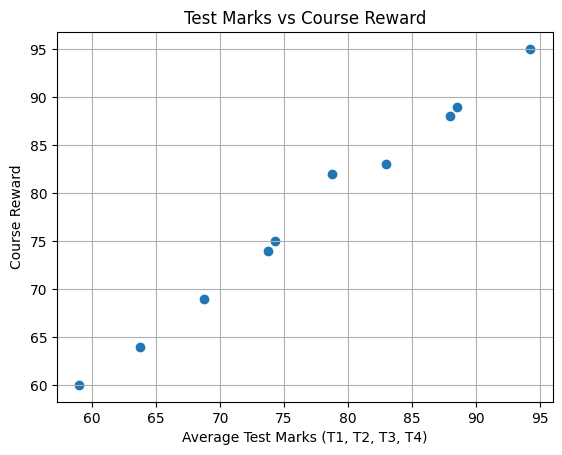

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

#10 sample records
data = {
    'T1': [78, 65, 90, 55, 72, 88, 60, 95, 70, 82],
    'T2': [80, 68, 85, 60, 75, 90, 65, 92, 73, 84],
    'T3': [75, 70, 88, 58, 78, 85, 62, 94, 76, 80],
    'T4': [82, 72, 91, 63, 70, 89, 68, 96, 78, 86],
    'Course_Reward': [82, 69, 89, 60, 74, 88, 64, 95, 75, 83]
}
df = pd.DataFrame(data)
print("Dataset:")
print(df)

#input features and target
X = df[['T1', 'T2', 'T3', 'T4']]
y = df['Course_Reward']

#Linear Regression model
model = LinearRegression()

#Training model
model.fit(X, y)

print("\nRegression Coefficients:")
print("T1:", model.coef_[0])
print("T2:", model.coef_[1])
print("T3:", model.coef_[2])
print("T4:", model.coef_[3])
print("Intercept:", model.intercept_)

#regression equation
print("\nRegression Equation:")
print(
    f"Course Reward = {model.intercept_:.2f} "
    f"+ ({model.coef_[0]:.2f} × T1) "
    f"+ ({model.coef_[1]:.2f} × T2) "
    f"+ ({model.coef_[2]:.2f} × T3) "
    f"+ ({model.coef_[3]:.2f} × T4)"
)
#Take new marks as input
print("\nEnter marks for prediction:")

T1 = float(input("Enter T1 marks: "))
T2 = float(input("Enter T2 marks: "))
T3 = float(input("Enter T3 marks: "))
T4 = float(input("Enter T4 marks: "))

#Predict Course Reward
new_data = pd.DataFrame({
    'T1': [T1],
    'T2': [T2],
    'T3': [T3],
    'T4': [T4]
})
prediction = model.predict(new_data)
print("\nPredicted Course Reward:", round(prediction[0], 2))

#Plot actual Course Reward vs average test marks
average_marks = df[['T1', 'T2', 'T3', 'T4']].mean(axis=1)

plt.scatter(average_marks, y)
plt.xlabel("Average Test Marks (T1, T2, T3, T4)")
plt.ylabel("Course Reward")
plt.title("Test Marks vs Course Reward")
plt.grid(True)
plt.show()

In [ ]:
!pip install xlrd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Concrete_Data.xls to Concrete_Data.xls



Polynomial Regression Equation:
Strength = 25.32 + (0.35 × Age) + (-0.00 × Age²)

Model Evaluation:
Mean Squared Error: 207.22
R² Score: 0.26

Enter age of concrete in days: 28
Predicted Concrete Compressive Strength: 34.31 MPa


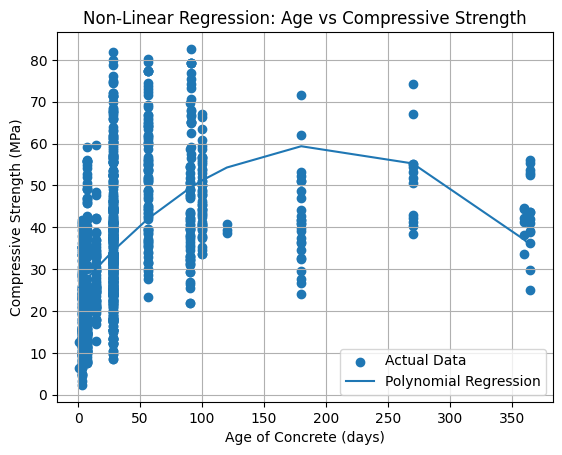

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#Load the dataset
df = pd.read_excel("Concrete_Data.xls")

#Select input and output
X = df[['Age (day)']]
y = df['Concrete compressive strength(MPa, megapascals) ']

#Converting input into polynomial features
polynomial = PolynomialFeatures(degree=2)

X_poly = polynomial.fit_transform(X)

#Create and train the Polynomial Regression model
model = LinearRegression()

model.fit(X_poly, y)

#Predicting output
y_pred = model.predict(X_poly)

print("\nPolynomial Regression Equation:")

print(
    f"Strength = {model.intercept_:.2f} "
    f"+ ({model.coef_[1]:.2f} × Age) "
    f"+ ({model.coef_[2]:.2f} × Age²)"
)

mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("\nModel Evaluation:")
print("Mean Squared Error:", round(mse, 2))
print("R² Score:", round(r2, 2))

#Take age as input for prediction
age = float(input("\nEnter age of concrete in days: "))

new_data = pd.DataFrame({
    'Age (day)': [age]
})
new_data_poly = polynomial.transform(new_data)

prediction = model.predict(new_data_poly)

print("Predicted Concrete Compressive Strength:",
      round(prediction[0], 2), "MPa")


plt.scatter(X, y, label="Actual Data")

#Sorting age values for a smooth curve
X_sorted = X.sort_values(by='Age (day)')

X_sorted_poly = polynomial.transform(X_sorted)

y_sorted_pred = model.predict(X_sorted_poly)

plt.plot(
    X_sorted,
    y_sorted_pred,
    label="Polynomial Regression"
)

plt.xlabel("Age of Concrete (days)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Non-Linear Regression: Age vs Compressive Strength")

plt.legend()
plt.grid(True)
plt.show()